# GEMAS — Kriging vs GNN for continental-scale soil Pb

Same protocol as the Jura notebook, applied to **GEMAS**: 2 213 agricultural topsoil
samples across 33 European countries, 4 742 × 4 302 km.

**Why this dataset is the interesting one.** On Jura (259 points, ~5 km across) kriging
won everywhere, and the reason was structural: a stationary Gaussian model was *correct*
there, so the optimal predictor was already linear and a flexible model could only lose.
GEMAS is the opposite regime — and §2 below shows two independent diagnostics saying the
field is **non-stationary**, which is the one situation where learned aggregation has a
principled reason to win.

**Order of business** (as asked): kriging baselines first, then the GNNs, then compare.

| § | content |
|---|---|
| 1 | load, merge, detection limits, log transform |
| 2 | **is it stationary?** unbounded variogram + madogram-vs-lag |
| 3 | spatial cross-validation |
| 4 | **kriging baselines** — OK(WLS), OK(CV-tuned), regression-kriging |
| 5 | **GNNs** — distance-only, +covariates, context-aware |
| 6 | hybrid: regression-kriging + GNN residual correction |
| 7 | comparison, figures, decision |

One baseline here that the Jura notebook lacked and that mattered: **OK with
CV-tuned parameters**. Fitting a variogram by weighted least squares optimises a
surrogate, not prediction error; under misspecification — which is precisely what §2
establishes — the best-fitting parameters are not the best-predicting ones. Without
that row in the table, any GNN "win" could just be the fitting criterion.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from scipy.optimize import minimize
from scipy.spatial.distance import cdist
import warnings, time

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = [8, 6]
DEV, RNG_SEED = "cpu", 0
np.random.seed(RNG_SEED); torch.manual_seed(RNG_SEED)

GEMAS_DIR = "/home/mboudouh/Downloads/ExtendedDataset_CSV/"
TARGET = "Pb"                 # log-transformed below
K_G = 10                      # graph neighbours
K_INNER, N_OUTER = 4, 5
N_SPATIAL_GROUPS = 15         # 3 held-out regions per outer fold
NMAXI, NMINI, RADIUS = 30, 1, 300.0          # km; 30th neighbour sits at ~167 km median
VARIO_NLAG, VARIO_FRAC = 25, 0.20            # fit window: 20% of the max distance
LAMBDA_GRID = [0.0, 0.25, 0.5, 0.75, 1.0]
print("torch", torch.__version__)

torch 2.14.1+cu130


In [2]:
def load_gemas(d=GEMAS_DIR):
    idt = pd.read_csv(d + "11 GEMAS Ap - Ident.csv")
    ar = pd.read_csv(d + "12a GEMAS Ap - AR PDL.csv")
    sp = pd.read_csv(d + "15a GEMAS Ap - pH-CEC-C-N-S-χ-CIA.csv")
    m = idt.merge(ar, on="ID").merge(sp, on="ID")
    m["xkm"] = m.X_LAEA / 1000.0            # LAEA metres -> km, equal-area so distances
    m["ykm"] = m.Y_LAEA / 1000.0            # are metrically meaningful
    return m


gem = load_gemas()
print(f"merged {gem.shape[0]} samples x {gem.shape[1]} columns, {gem.Country.nunique()} countries")

# ---- detection limits: GEMAS encodes "below DL" as a NEGATIVE value = -DL -----------
v = gem[TARGET].to_numpy(float)
bdl = v < 0
if bdl.any():
    v = v.copy(); v[bdl] = np.abs(v[bdl]) / 2.0      # conventional DL/2 substitution
    print(f"{bdl.sum()} values below detection limit -> DL/2")
keep = np.isfinite(v) & (v > 0)
print(f"{(~keep).sum()} rows dropped (missing target)")

G = gem.loc[keep].reset_index(drop=True)
Y_RAW = v[keep]
Y = np.log(Y_RAW)                                     # log scale: see §2
XY = np.c_[G.xkm, G.ykm].astype(float)
print(f"\nmodelling log({TARGET}) on {len(Y)} samples")
print(f"  raw  {TARGET}: median {np.median(Y_RAW):.2f} mg/kg, max {Y_RAW.max():.0f}, "
      f"skew {pd.Series(Y_RAW).skew():.1f}, kurtosis {pd.Series(Y_RAW).kurt():.0f}")
print(f"  log  {TARGET}: mean {Y.mean():.3f}, var {Y.var():.4f}, "
      f"skew {pd.Series(Y).skew():.2f}, kurtosis {pd.Series(Y).kurt():.2f}")
print("  -> the log transform is not optional here; the raw variable is far too")
print("     heavy-tailed for a linear predictor.")

merged 2213 samples x 90 columns, 33 countries
1 rows dropped (missing target)

modelling log(Pb) on 2212 samples
  raw  Pb: median 15.40 mg/kg, max 1310, skew 21.9, kurtosis 658
  log  Pb: mean 2.724, var 0.4895, skew 0.33, kurtosis 2.05
  -> the log transform is not optional here; the raw variable is far too
     heavy-tailed for a linear predictor.


In [3]:
# ---- covariates -------------------------------------------------------------------
NUM_COVS = ["AMT_1970-2000", "APS_1970-2000", "Altitude", "PD_2005",
            "pH_CaCl2", "CEC", "TOC", "CIA"]
CAT_COVS = {"Climate": ["Temp", "BoTe", "SpBo", "Medi"],
            "Soilclass": ["l", "ll", "s", "m", "ss"],
            "Litho": sorted(G.Litho.dropna().unique().tolist())}

print("numeric covariates (missing counts):")
for c in NUM_COVS:
    print(f"  {c:16s} {G[c].isna().sum():4d}")
print("categorical covariates (fixed one-hot schema, unknown -> all zeros):")
for c, lv in CAT_COVS.items():
    print(f"  {c:16s} {len(lv):3d} levels")


def build_covariates(df, idx_fit):
    """Numeric covariates imputed with FIT-subset medians, then one-hot categoricals.
    PD is log1p'd (population density spans 5 orders of magnitude)."""
    out, names = [], []
    for c in NUM_COVS:
        x = df[c].to_numpy(float).copy()
        if c == "PD_2005":
            x = np.log1p(np.clip(x, 0, None))
        med = np.nanmedian(x[idx_fit])
        x[~np.isfinite(x)] = med
        out.append(x); names.append(c)
    for c, levels in CAT_COVS.items():
        col = df[c].to_numpy()
        for lv in levels:
            out.append((col == lv).astype(float)); names.append(f"{c}={lv}")
    return np.column_stack(out), names


C_ALL, COV_NAMES = build_covariates(G, np.arange(len(G)))
print(f"\ncovariate matrix: {C_ALL.shape[1]} columns")

numeric covariates (missing counts):
  AMT_1970-2000       0
  APS_1970-2000       0
  Altitude            0
  PD_2005             0
  pH_CaCl2          104
  CEC               104
  TOC                13
  CIA                 0
categorical covariates (fixed one-hot schema, unknown -> all zeros):
  Climate            4 levels
  Soilclass          5 levels
  Litho             13 levels

covariate matrix: 30 columns


## 2. Is the field stationary?

This section decides whether the rest of the notebook is worth running, so it comes
before any model. Two parameter-free diagnostics.

**(a) Does the variogram reach a sill?** A second-order stationary field has finite
variance, so $\gamma(h)$ must flatten at $\mathrm{Var}(Z)$. If $\gamma$ keeps climbing
past the variance, no stationary model with a finite sill can describe the field.

**(b) Is the madogram ratio constant?** For *any* Gaussian field,
$\gamma_2(h)/\gamma_1(h)^2=\pi$ at **every** lag. A ratio that drifts with $h$ is
evidence against joint Gaussianity *and* against stationarity, since under
stationarity the ratio cannot depend on $h$ at all.

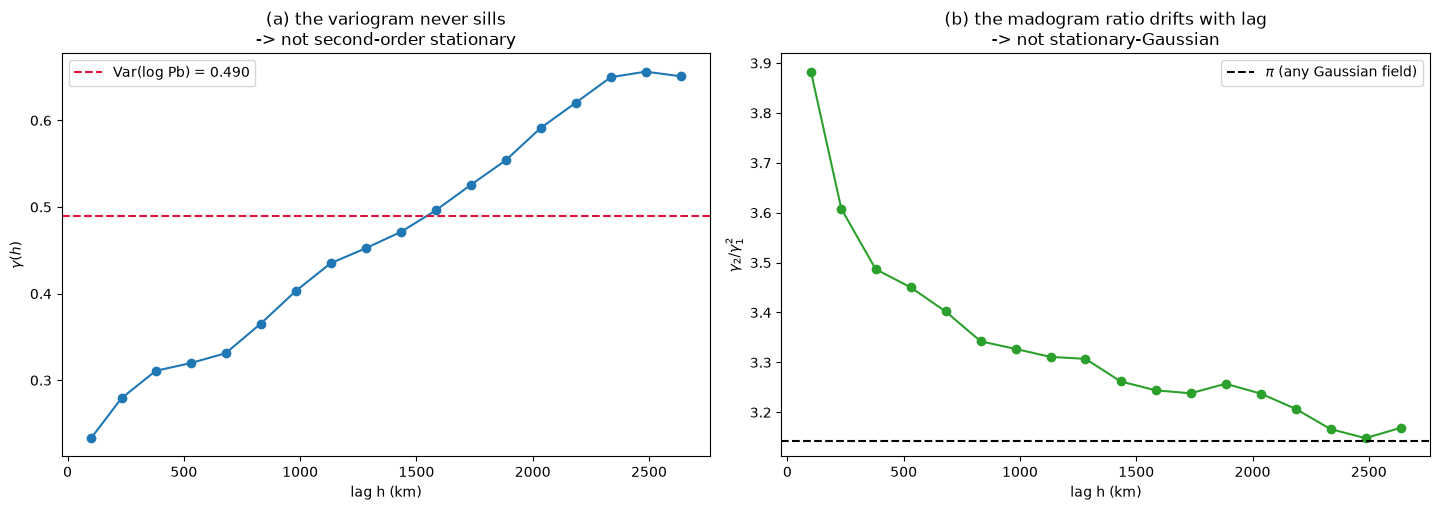

total variance of log(Pb)          : 0.4895
gamma at the shortest lag (101 km)   : 0.2332
gamma at the longest lag  (2636 km) : 0.6509
gamma EXCEEDS the total variance beyond ~1583 km -> unbounded variogram
madogram ratio: 3.883 at 101 km  ->  3.169 at 2636 km   (pi = 3.142)

Both diagnostics point the same way: a single global stationary variogram is
structurally misspecified on this field. Ordinary kriging is therefore being
asked to do something its model cannot represent -- which is exactly the
condition under which a learned aggregator has a reason to win.

Consequence for the baseline: the variogram must be fitted on a SHORT window
(here 20% of the maximum distance) and kriging must use a moving
neighbourhood, so it only ever assumes stationarity LOCALLY. That is the
standard practical hedge and it makes the baseline much stronger.


In [4]:
def variogram_cloud_binned(xy, z, nbins=18, frac=0.5, min_pairs=200):
    """Binned 2nd- and 1st-order variograms (semivariogram and madogram)."""
    d = cdist(xy, xy)
    iu = np.triu_indices_from(d, k=1)
    dv = d[iu]
    diff = np.abs(np.subtract.outer(z, z)[iu])
    edges = np.linspace(0, frac * d.max(), nbins + 1)
    rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (dv >= lo) & (dv < hi)
        if m.sum() >= min_pairs:
            g2 = 0.5 * np.mean(diff[m] ** 2)
            g1 = 0.5 * np.mean(diff[m])
            rows.append([dv[m].mean(), g2, g1, g2 / g1 ** 2, m.sum()])
    return np.array(rows)


VG = variogram_cloud_binned(XY, Y)
var_tot = float(np.var(Y))

fig, ax = plt.subplots(1, 2, figsize=(14.5, 5.2))
ax[0].plot(VG[:, 0], VG[:, 1], "-o", color="#1f77b4")
ax[0].axhline(var_tot, color="crimson", ls="--",
              label=f"Var(log {TARGET}) = {var_tot:.3f}")
ax[0].set_xlabel("lag h (km)"); ax[0].set_ylabel(r"$\gamma(h)$")
ax[0].set_title("(a) the variogram never sills\n-> not second-order stationary")
ax[0].legend()

ax[1].plot(VG[:, 0], VG[:, 3], "-o", color="#2ca02c")
ax[1].axhline(np.pi, color="k", ls="--", label=r"$\pi$ (any Gaussian field)")
ax[1].set_xlabel("lag h (km)"); ax[1].set_ylabel(r"$\gamma_2/\gamma_1^2$")
ax[1].set_title("(b) the madogram ratio drifts with lag\n-> not stationary-Gaussian")
ax[1].legend()
plt.tight_layout(); plt.show()

cross = VG[VG[:, 1] > var_tot]
print(f"total variance of log({TARGET})          : {var_tot:.4f}")
print(f"gamma at the shortest lag ({VG[0,0]:.0f} km)   : {VG[0,1]:.4f}")
print(f"gamma at the longest lag  ({VG[-1,0]:.0f} km) : {VG[-1,1]:.4f}")
if len(cross):
    print(f"gamma EXCEEDS the total variance beyond ~{cross[0,0]:.0f} km "
          f"-> unbounded variogram")
print(f"madogram ratio: {VG[0,3]:.3f} at {VG[0,0]:.0f} km  ->  "
      f"{VG[-1,3]:.3f} at {VG[-1,0]:.0f} km   (pi = {np.pi:.3f})")
print()
print("Both diagnostics point the same way: a single global stationary variogram is")
print("structurally misspecified on this field. Ordinary kriging is therefore being")
print("asked to do something its model cannot represent -- which is exactly the")
print("condition under which a learned aggregator has a reason to win.")
print()
print("Consequence for the baseline: the variogram must be fitted on a SHORT window")
print(f"(here {VARIO_FRAC:.0%} of the maximum distance) and kriging must use a moving")
print("neighbourhood, so it only ever assumes stationarity LOCALLY. That is the")
print("standard practical hedge and it makes the baseline much stronger.")

## 3. Spatial cross-validation

15 KMeans groups, `GroupKFold(5)`, so each fold holds out three whole regions
(~440 samples). A random split would place test points a median 41 km from training
points — inside the correlation range — and flatter every interpolator.

  outer fold 0: train 1756  test  456  regions [np.int64(1), np.int64(10), np.int64(11)]
  outer fold 1: train 1796  test  416  regions [np.int64(8), np.int64(9), np.int64(14)]
  outer fold 2: train 1764  test  448  regions [np.int64(3), np.int64(4), np.int64(12)]
  outer fold 3: train 1759  test  453  regions [np.int64(2), np.int64(7), np.int64(13)]
  outer fold 4: train 1773  test  439  regions [np.int64(0), np.int64(5), np.int64(6)]


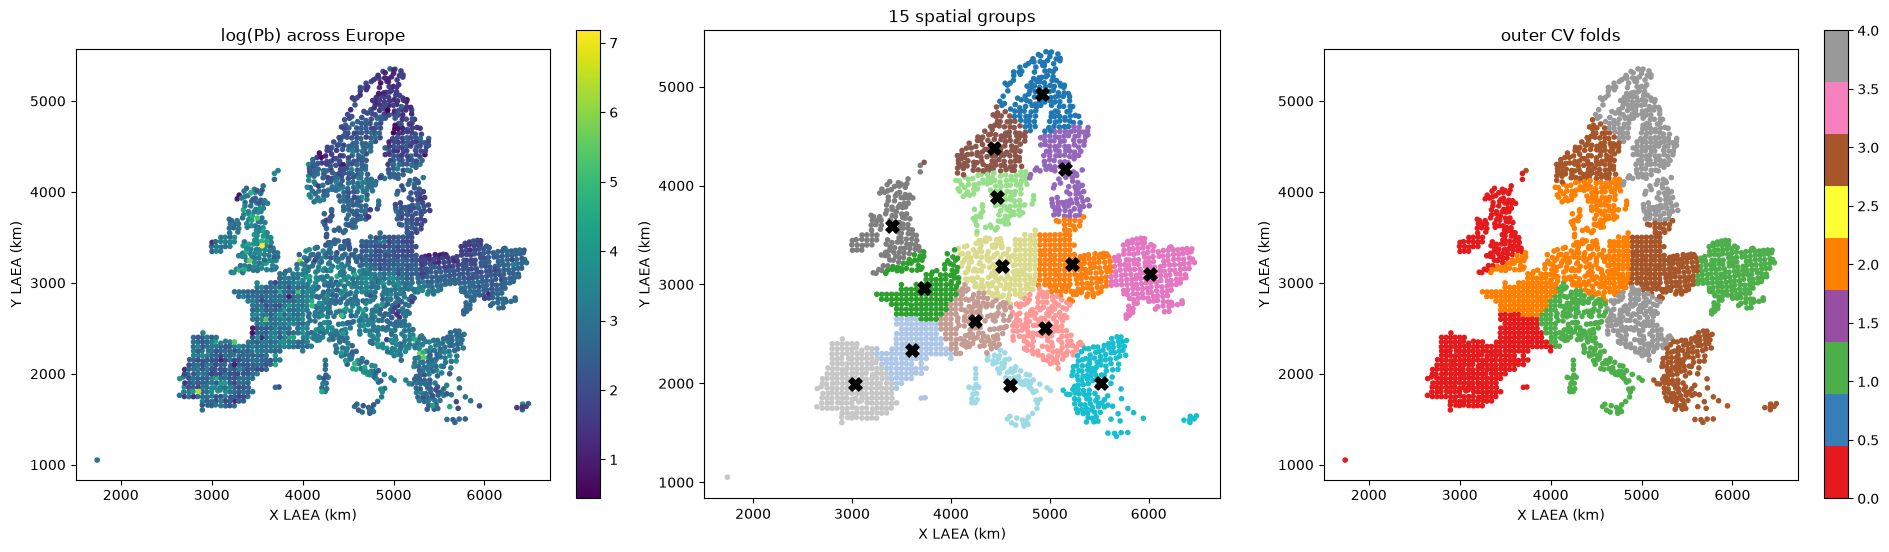

In [5]:
def kmeans(X, k, seed=0, iters=150):
    rs = np.random.default_rng(seed)
    C = [X[rs.integers(len(X))]]
    for _ in range(k - 1):
        d2 = np.min(cdist(X, np.array(C)) ** 2, axis=1)
        C.append(X[rs.choice(len(X), p=d2 / d2.sum())])
    C = np.array(C)
    for _ in range(iters):
        lab = np.argmin(cdist(X, C), axis=1)
        nC = np.array([X[lab == j].mean(0) if (lab == j).any() else C[j] for j in range(k)])
        if np.allclose(nC, C):
            break
        C = nC
    return np.argmin(cdist(X, C), axis=1), C


def group_kfold(groups, n_splits, seed=0):
    uniq, counts = np.unique(groups, return_counts=True)
    fold_of, load = {}, np.zeros(n_splits, int)
    for gi in np.argsort(-counts):
        f = int(np.argmin(load)); fold_of[uniq[gi]] = f; load[f] += counts[gi]
    fid = np.array([fold_of[g] for g in groups])
    return [(np.where(fid != f)[0], np.where(fid == f)[0]) for f in range(n_splits)]


GROUPS, CENT = kmeans(XY, N_SPATIAL_GROUPS, seed=RNG_SEED)
OUTER = group_kfold(GROUPS, N_OUTER, seed=RNG_SEED)
for f, (tr, te) in enumerate(OUTER):
    print(f"  outer fold {f}: train {len(tr):4d}  test {len(te):4d}  "
          f"regions {sorted(set(GROUPS[te]))}")

fold_id = np.zeros(len(Y), int)
for f, (_, te) in enumerate(OUTER):
    fold_id[te] = f
fig, ax = plt.subplots(1, 3, figsize=(19, 5.4))
s0 = ax[0].scatter(XY[:, 0], XY[:, 1], c=Y, cmap="viridis", s=9)
ax[0].set_title(f"log({TARGET}) across Europe"); plt.colorbar(s0, ax=ax[0], fraction=.046)
ax[1].scatter(XY[:, 0], XY[:, 1], c=GROUPS, cmap="tab20", s=9)
ax[1].scatter(CENT[:, 0], CENT[:, 1], c="k", marker="X", s=90)
ax[1].set_title(f"{N_SPATIAL_GROUPS} spatial groups")
s2 = ax[2].scatter(XY[:, 0], XY[:, 1], c=fold_id, cmap="Set1", s=9)
ax[2].set_title("outer CV folds"); plt.colorbar(s2, ax=ax[2], fraction=.046)
for a in ax:
    a.set_aspect("equal"); a.set_xlabel("X LAEA (km)"); a.set_ylabel("Y LAEA (km)")
plt.tight_layout(); plt.show()

## 4. Kriging baselines

Three, in increasing strength. The third is the one a GNN actually has to beat.

1. **OK (WLS)** — nugget+spherical fitted by weighted least squares on the binned
   variogram. What everyone reports.
2. **OK (CV-tuned)** — the *same* model family, but the three parameters chosen to
   minimise held-out prediction error inside the training pool. Under the
   misspecification §2 established, these are not the same parameters.
3. **Regression-kriging** — linear drift in the covariates (climate, parent material,
   pH, population density…), then OK on the residuals. The classical answer to a
   non-stationary *mean*, and the pattern used in your notebook's `ext_drift` section.

In [6]:
def vario_spherical(h, sill, rng_, nugget):
    h = np.asarray(h, float); a = max(rng_, 1e-9)
    t = np.clip(h / a, 0.0, 1.0)
    return np.where(h == 0.0, 0.0, nugget + sill * (1.5 * t - 0.5 * t ** 3))


def fit_variogram_model(xy, z, nlag=VARIO_NLAG, frac=VARIO_FRAC):
    """WLS on a SHORT window -- mandatory here, since the variogram is unbounded (§2)."""
    d = cdist(xy, xy)
    iu = np.triu_indices_from(d, k=1)
    dv, gv = d[iu], 0.5 * np.subtract.outer(z, z)[iu] ** 2
    hmax = frac * d.max()
    edges = np.linspace(0, hmax, nlag + 1)
    rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (dv >= lo) & (dv < hi)
        if m.sum() >= 30:
            rows.append([dv[m].mean(), gv[m].mean(), m.sum()])
    vg = np.array(rows)
    var = float(np.var(z)) + 1e-12
    if len(vg) < 4:
        return var, hmax / 3, 0.1 * var

    def cost(p):
        s, r_, n_ = np.abs(p)
        return float(np.sum(vg[:, 2] * (vg[:, 1] - vario_spherical(vg[:, 0], s, r_, n_)) ** 2))

    best = None
    for r0 in (0.2 * hmax, 0.5 * hmax, 0.9 * hmax):
        res = minimize(cost, [var, r0, 0.3 * var], method="L-BFGS-B",
                       bounds=[(1e-9, 5 * var), (0.02 * hmax, 1.2 * hmax), (0.0, 0.9 * var)])
        if best is None or res.fun < best.fun:
            best = res
    s, r_, n_ = np.abs(best.x)
    return float(s), float(r_), float(n_)


def ok_predict(xy_s, z_s, xy_q, vm, nmaxi=NMAXI, nmini=NMINI, radius=RADIUS):
    """Ordinary kriging, moving neighbourhood -> stationarity assumed only locally."""
    d0 = cdist(xy_q, xy_s)
    order = np.argsort(d0, axis=1)
    est = np.empty(len(xy_q))
    for t in range(len(xy_q)):
        cand = order[t][d0[t, order[t]] <= radius][:nmaxi]
        if len(cand) < nmini:
            cand = order[t][:max(nmini, 1)]
        j = cand; m = len(j)
        if m == 1:
            est[t] = z_s[j[0]]; continue
        A = np.ones((m + 1, m + 1)); A[m, m] = 0.0
        A[:m, :m] = vm(cdist(xy_s[j], xy_s[j]))
        g0 = vm(d0[t, j])
        sol = np.linalg.lstsq(A, np.append(g0, 1.0), rcond=None)[0]
        est[t] = float(sol[:m] @ z_s[j])
    bad = ~np.isfinite(est)
    if bad.any():
        est[bad] = z_s.mean()
    return est


def fit_kriging_predict(xy_s, z_s, xy_q, params=None):
    """params=None -> fit the variogram by WLS on the support set first."""
    if params is None:
        params = fit_variogram_model(xy_s, z_s)
    s, r_, n_ = params
    return ok_predict(xy_s, z_s, xy_q, lambda h: vario_spherical(h, s, r_, n_))


def tune_kriging_params(xy_s, z_s, p0, seed=0, n_val=350, maxiter=45):
    """Choose (sill, range, nugget) by held-out PREDICTION error inside the support set.

    The lesson from the Jura work: WLS optimises a surrogate. Under misspecification the
    best-fitting parameters are not the best-predicting ones, and skipping this baseline
    makes any learned method look better than it is.
    """
    rs = np.random.default_rng(seed)
    p = rs.permutation(len(z_s))
    val, fit = p[:min(n_val, len(p) // 4)], p[min(n_val, len(p) // 4):]

    def obj(q):
        s, r_, n_ = np.abs(q)
        pr = ok_predict(xy_s[fit], z_s[fit], xy_s[val],
                        lambda h: vario_spherical(h, s, r_, n_))
        return float(np.sqrt(np.mean((pr - z_s[val]) ** 2)))

    res = minimize(obj, list(p0), method="Nelder-Mead",
                   options=dict(maxiter=maxiter, fatol=1e-4, xatol=1e-2))
    return tuple(np.abs(res.x))


def regression_kriging(xy_s, z_s, C_s, xy_q, C_q, params=None):
    """Linear drift in the covariates, then ordinary kriging of the residuals."""
    A = np.column_stack([np.ones(len(z_s)), C_s])
    beta = np.linalg.lstsq(A, z_s, rcond=None)[0]
    resid = z_s - A @ beta
    kr = fit_kriging_predict(xy_s, resid, xy_q, params)
    trend_q = np.column_stack([np.ones(len(xy_q)), C_q]) @ beta
    return trend_q + kr, beta


def scores(z, p):
    e = np.asarray(p, float) - np.asarray(z, float)
    return dict(RMSE=float(np.sqrt(np.mean(e ** 2))), MAE=float(np.mean(np.abs(e))),
                Bias=float(np.mean(e)))


_s, _r, _n = fit_variogram_model(XY, Y)
print(f"global WLS fit on the {VARIO_FRAC:.0%} window: sill={_s:.4f}  range={_r:.0f} km  "
      f"nugget={_n:.4f}")
print(f"  nugget / (nugget+sill) = {_n/(_n+_s):.2f}  "
      f"<- the short-range noise fraction")
_t = time.time(); _p = fit_kriging_predict(XY[:1800], Y[:1800], XY[1800:]); _el = time.time()-_t
print(f"wrapper OK: {len(_p)} predictions in {_el:.2f}s")

global WLS fit on the 20% window: sill=0.1887  range=1303 km  nugget=0.2177
  nugget / (nugget+sill) = 0.54  <- the short-range noise fraction


wrapper OK: 412 predictions in 0.36s


## 5. The GNNs

All three predict log(Pb) at a query node as a weighted combination of its `K_G`
nearest **training** nodes. They differ only in what the attention is allowed to see —
which is the whole question, because *shared parameters do not mean constant weights*:
the same MLP emits different weights where its inputs differ, but only if it is given a
local signal to condition on.

| model | attention sees | can it be non-stationary? |
|---|---|---|
| **A** | distance only | **no** — one global weight profile, same as kriging |
| **B** | + the neighbour's and target's covariates | yes, via covariates |
| **C** | + neighbour values and neighbourhood statistics | yes, via local roughness |

A is the control. If B or C beats A, the gain is specifically attributable to
conditioning on local context, not to flexibility in the decay shape.

The softmax keeps $\sum_j\alpha_{ij}=1$, which is kriging's unbiasedness constraint,
though it also forbids negative weights — on Jura that cost ~4% because near-duplicate
samples had to be screened. Here the median nearest neighbour is 41 km on a near-regular
grid, so there is almost no redundancy to screen and the constraint should cost little.

In [7]:
def knn_graph(xy_q, xy_s, k=K_G, exclude_self=False):
    d = cdist(xy_q, xy_s)
    if exclude_self:
        d = d.copy(); np.fill_diagonal(d, np.inf)
    kk = max(1, min(k, xy_s.shape[0] - (1 if exclude_self else 0)))
    nbr = np.argsort(d, axis=1)[:, :kk]
    return nbr, np.take_along_axis(d, nbr, axis=1)


def make_batch(xy_q, xy_s, z_s, C_s, C_q, d_scale, k=K_G, exclude_self=False):
    nbr, dist = knn_graph(xy_q, xy_s, k, exclude_self)
    return dict(
        dist=torch.tensor(dist / d_scale, dtype=torch.float32, device=DEV),
        y_nbr=torch.tensor(z_s[nbr], dtype=torch.float32, device=DEV),
        c_nbr=torch.tensor(C_s[nbr], dtype=torch.float32, device=DEV),
        c_self=torch.tensor(C_q, dtype=torch.float32, device=DEV),
    )


def edge_feats(d):
    return torch.stack([d, d ** 2, torch.exp(-d), torch.log1p(d)], dim=-1)


class AttnGNN(nn.Module):
    """mode 'A' distance only | 'B' + covariates | 'C' + values and local statistics."""

    def __init__(self, mode, n_cov, hidden=48, p_drop=0.1):
        super().__init__()
        self.mode = mode
        d_edge = 4
        d_att = {"A": d_edge,
                 "B": d_edge + 2 * n_cov,
                 "C": d_edge + 2 * n_cov + 1 + 3}[mode]
        self.att = nn.Sequential(nn.Linear(d_att, hidden), nn.SiLU(),
                                 nn.Dropout(p_drop), nn.Linear(hidden, hidden), nn.SiLU(),
                                 nn.Linear(hidden, 1))
        # residual head on top of the attention-weighted mean (zero-init => starts as
        # a pure kriging-like weighted average)
        self.head = nn.Sequential(nn.Linear(d_att, hidden), nn.SiLU(),
                                  nn.Dropout(p_drop), nn.Linear(hidden, 1))
        nn.init.zeros_(self.head[-1].weight); nn.init.zeros_(self.head[-1].bias)
        self.use_head = mode != "A"

    def _inputs(self, g):
        d, y = g["dist"], g["y_nbr"]
        K = d.shape[1]
        parts = [edge_feats(d)]
        if self.mode in ("B", "C"):
            parts += [g["c_nbr"], g["c_self"].unsqueeze(1).expand(-1, K, -1)]
        if self.mode == "C":
            ctx = torch.stack([y.std(-1), y.mean(-1), d.mean(-1)], -1)
            parts += [y.unsqueeze(-1), ctx.unsqueeze(1).expand(-1, K, -1)]
        return torch.cat(parts, dim=-1)

    def forward(self, g, return_alpha=False):
        x = self._inputs(g)
        alpha = torch.softmax(self.att(x).squeeze(-1), dim=-1)
        pred = (alpha * g["y_nbr"]).sum(-1)
        if self.use_head:
            pred = pred + (alpha.unsqueeze(-1) * self.head(x)).sum(1).squeeze(-1)
        return (pred, alpha) if return_alpha else pred


def train_attn(mode, n_cov, g_fit, y_fit, g_es, y_es, epochs=700, lr=3e-3, wd=1e-4,
               patience=150, seed=0, hidden=48):
    torch.manual_seed(seed)
    m = AttnGNN(mode, n_cov, hidden=hidden)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=wd)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    lf = nn.MSELoss()
    best, bst, bep = np.inf, None, 0
    for ep in range(epochs):
        m.train(); opt.zero_grad(); lf(m(g_fit), y_fit).backward()
        nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); sch.step()
        m.eval()
        with torch.no_grad():
            v = lf(m(g_es), y_es).item()
        if v < best - 1e-8:
            best, bep = v, ep
            bst = {k: t.detach().clone() for k, t in m.state_dict().items()}
        elif ep - bep > patience:
            break
    if bst is not None:
        m.load_state_dict(bst)
    m.eval()
    return m, best, bep


print("GNN parameter counts:")
for mo in "ABC":
    print(f"  model {mo}: {sum(p.numel() for p in AttnGNN(mo, C_ALL.shape[1]).parameters()):6d}")

GNN parameter counts:
  model A:   2930
  model B:   8690
  model C:   9074


## 6. Hybrid: regression-kriging + GNN residual correction

The architecture from the `hybrid_kriging_edge_aware_gnn_algorithm` spec, carried over:
the GNN predicts the **out-of-fold** residual left by the kriging baseline, and
$\widehat z_H=\widehat z_K+\lambda\widehat r_G$ with $\lambda$ chosen inside the
training pool. Support nodes carry their OOF residual as a feature, query nodes carry a
zero placeholder plus a mask.

In-sample residuals are useless as targets — kriging interpolates its own samples
exactly, so they are identically zero. Cross-fitting is what makes the method exist.

In [8]:
def crossfit_oof(xy, z, C, k_inner=K_INNER, seed=0, use_cov=False):
    """Spatial out-of-fold kriging predictions and residuals for a support set."""
    k_oof = np.full(len(z), np.nan)
    g, _ = kmeans(xy, max(k_inner, 2), seed=seed + 3)
    for _, H in group_kfold(g, k_inner, seed=seed):
        A = np.setdiff1d(np.arange(len(z)), H)
        if len(A) < 50:
            continue
        if use_cov:
            k_oof[H], _ = regression_kriging(xy[A], z[A], C[A], xy[H], C[H])
        else:
            k_oof[H] = fit_kriging_predict(xy[A], z[A], xy[H])
    bad = ~np.isfinite(k_oof)
    if bad.any():
        k_oof[bad] = z[~bad].mean() if (~bad).any() else z.mean()
    return k_oof, z - k_oof


class ResidGNN(nn.Module):
    """Predicts a standardised residual correction from neighbour OOF residuals."""

    def __init__(self, n_cov, hidden=48, p_drop=0.1):
        super().__init__()
        d_in = 4 + 1 + 1 + 2 * n_cov          # edge, nbr residual, mask, covariates
        self.att = nn.Sequential(nn.Linear(d_in, hidden), nn.SiLU(),
                                 nn.Linear(hidden, 1))
        self.msg = nn.Sequential(nn.Linear(d_in, hidden), nn.SiLU(), nn.Dropout(p_drop),
                                 nn.Linear(hidden, hidden), nn.SiLU())
        self.out = nn.Sequential(nn.Linear(hidden, hidden), nn.SiLU(),
                                 nn.Dropout(p_drop), nn.Linear(hidden, 1))
        nn.init.zeros_(self.out[-1].weight); nn.init.zeros_(self.out[-1].bias)

    def forward(self, g):
        d, r = g["dist"], g["r_nbr"]
        K = d.shape[1]
        x = torch.cat([edge_feats(d), r.unsqueeze(-1), g["m_nbr"].unsqueeze(-1),
                       g["c_nbr"], g["c_self"].unsqueeze(1).expand(-1, K, -1)], dim=-1)
        a = torch.softmax(self.att(x).squeeze(-1), dim=-1)
        h = (a.unsqueeze(-1) * self.msg(x)).sum(1)
        return self.out(h).squeeze(-1)


def make_resid_batch(xy_q, xy_s, r_s, C_s, C_q, d_scale, r_scale, k=K_G, exclude_self=False):
    nbr, dist = knn_graph(xy_q, xy_s, k, exclude_self)
    return dict(
        dist=torch.tensor(dist / d_scale, dtype=torch.float32, device=DEV),
        r_nbr=torch.tensor(r_s[nbr] / r_scale, dtype=torch.float32, device=DEV),
        m_nbr=torch.ones(len(xy_q), nbr.shape[1], dtype=torch.float32, device=DEV),
        c_nbr=torch.tensor(C_s[nbr], dtype=torch.float32, device=DEV),
        c_self=torch.tensor(C_q, dtype=torch.float32, device=DEV),
    )


def train_resid(n_cov, g_fit, t_fit, g_es, t_es, epochs=700, lr=3e-3, wd=1e-3,
                patience=150, seed=0):
    torch.manual_seed(seed)
    m = ResidGNN(n_cov)
    opt = torch.optim.AdamW(m.parameters(), lr=lr, weight_decay=wd)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    lf = nn.MSELoss(); best, bst, bep = np.inf, None, 0
    for ep in range(epochs):
        m.train(); opt.zero_grad(); lf(m(g_fit), t_fit).backward()
        nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); sch.step()
        m.eval()
        with torch.no_grad():
            v = lf(m(g_es), t_es).item()
        if v < best - 1e-8:
            best, bep = v, ep
            bst = {k: t.detach().clone() for k, t in m.state_dict().items()}
        elif ep - bep > patience:
            break
    if bst is not None:
        m.load_state_dict(bst)
    m.eval()
    return m

## 7. The comparison

One function runs every method on one outer fold. Everything — variogram fits,
covariate imputation medians, scalers, early stopping, parameter tuning and
$\lambda$ — is derived from the training pool $T$ only. The held-out regions $V$ are
touched exactly once, to score.

In [9]:
def run_fold(tr, te, seed=0, k_g=K_G, verbose=True):
    xy_T, xy_V = XY[tr], XY[te]
    z_T, z_V = Y[tr], Y[te]

    # covariates re-imputed with TRAIN medians, then standardised on TRAIN
    C_full, cov_names = build_covariates(G, tr)

    # DROP columns with no variance in the training pool. A one-hot level that appears
    # ONLY in the held-out regions has train std = 0, and dividing by (std + 1e-9) turns
    # a single test sample into a feature of ~1e9 that destroys the whole fold. On this
    # data exactly that happens: 'Litho=Ds' is absent from fold 1's training pool and
    # present in one test sample.
    sd_raw = C_full[tr].std(0)
    live = sd_raw > 1e-8
    if (~live).any():
        print(f"    dropped {int((~live).sum())} zero-variance covariate(s): "
              f"{[cov_names[i] for i in np.where(~live)[0]]}")
    C_full = C_full[:, live]
    c_mu, c_sd = C_full[tr].mean(0), C_full[tr].std(0)
    C_T, C_V = (C_full[tr] - c_mu) / c_sd, (C_full[te] - c_mu) / c_sd
    n_cov = C_T.shape[1]
    assert np.isfinite(C_T).all() and np.isfinite(C_V).all(), "non-finite covariates"
    assert np.abs(C_V).max() < 1e3, f"covariate blow-up: max |z| = {np.abs(C_V).max():.1e}"

    d_scale = float(np.median(knn_graph(xy_T, xy_T, k_g, exclude_self=True)[1]))
    out = {}

    # ---------- baselines ----------------------------------------------------------
    p_wls = fit_variogram_model(xy_T, z_T)
    out["OK (WLS)"] = fit_kriging_predict(xy_T, z_T, xy_V, p_wls)

    p_cv = tune_kriging_params(xy_T, z_T, p_wls, seed=seed)
    out["OK (CV-tuned)"] = fit_kriging_predict(xy_T, z_T, xy_V, p_cv)

    out["Regression-kriging"], _ = regression_kriging(xy_T, z_T, C_T, xy_V, C_V)

    # ---------- GNNs ---------------------------------------------------------------
    rs = np.random.default_rng(seed)
    gl, _ = kmeans(xy_T, 5, seed=seed + 5)              # spatial early-stopping split
    es_grp = np.argsort(np.bincount(gl, minlength=5))[0]
    es_i = np.where(gl == es_grp)[0]
    fit_i = np.setdiff1d(np.arange(len(z_T)), es_i)

    g_fit = make_batch(xy_T[fit_i], xy_T[fit_i], z_T[fit_i], C_T[fit_i], C_T[fit_i],
                       d_scale, k_g, exclude_self=True)
    g_es = make_batch(xy_T[es_i], xy_T[fit_i], z_T[fit_i], C_T[fit_i], C_T[es_i],
                      d_scale, k_g)
    g_V = make_batch(xy_V, xy_T, z_T, C_T, C_V, d_scale, k_g)
    y_fit = torch.tensor(z_T[fit_i], dtype=torch.float32, device=DEV)
    y_es = torch.tensor(z_T[es_i], dtype=torch.float32, device=DEV)

    for mode, nm in (("A", "GNN A (distance only)"), ("B", "GNN B (+covariates)"),
                     ("C", "GNN C (context-aware)")):
        m, _, _ = train_attn(mode, n_cov, g_fit, y_fit, g_es, y_es, seed=seed)
        with torch.no_grad():
            out[nm] = m(g_V).cpu().numpy()

    # ---------- hybrid: regression-kriging + GNN residual correction ---------------
    k_oof_T, r_oof_T = crossfit_oof(xy_T, z_T, C_T, seed=seed, use_cov=True)
    r_scale = max(float(np.std(r_oof_T)), 1e-3)

    k_oof_f, r_oof_f = crossfit_oof(xy_T[fit_i], z_T[fit_i], C_T[fit_i], seed=seed, use_cov=True)
    k_es, _ = regression_kriging(xy_T[fit_i], z_T[fit_i], C_T[fit_i], xy_T[es_i], C_T[es_i])

    gh_fit = make_resid_batch(xy_T[fit_i], xy_T[fit_i], r_oof_f, C_T[fit_i], C_T[fit_i],
                              d_scale, r_scale, k_g, exclude_self=True)
    gh_es = make_resid_batch(xy_T[es_i], xy_T[fit_i], r_oof_f, C_T[fit_i], C_T[es_i],
                             d_scale, r_scale, k_g)
    t_fit = torch.tensor(r_oof_f / r_scale, dtype=torch.float32, device=DEV)
    t_es = torch.tensor((z_T[es_i] - k_es) / r_scale, dtype=torch.float32, device=DEV)

    mh = train_resid(n_cov, gh_fit, t_fit, gh_es, t_es, seed=seed)
    with torch.no_grad():
        corr_es = r_scale * mh(gh_es).cpu().numpy()
    lam_scores = {l: float(np.sqrt(np.mean((k_es + l * corr_es - z_T[es_i]) ** 2)))
                  for l in LAMBDA_GRID}
    lam = min(lam_scores, key=lam_scores.get)

    gh_V = make_resid_batch(xy_V, xy_T, r_oof_T, C_T, C_V, d_scale, r_scale, k_g)
    with torch.no_grad():
        corr_V = r_scale * mh(gh_V).cpu().numpy()
    out[f"Hybrid RK+GNN"] = out["Regression-kriging"] + lam * corr_V

    # a prediction far outside the observed range means something broke; say so loudly
    lo, hi = z_T.min() - 5 * z_T.std(), z_T.max() + 5 * z_T.std()
    for nm, v in out.items():
        if not np.isfinite(v).all() or v.min() < lo or v.max() > hi:
            print(f"    [WARN] '{nm}' produced implausible values "
                  f"[{np.nanmin(v):.3g}, {np.nanmax(v):.3g}] outside [{lo:.2f}, {hi:.2f}]")

    if verbose:
        print(f"    WLS range {p_wls[1]:5.0f} km -> CV-tuned {p_cv[1]:5.0f} km | "
              f"lambda {lam} | " +
              "  ".join(f"{k.split()[0]}={scores(z_V, v)['RMSE']:.4f}"
                        for k, v in list(out.items())[:3]))
    return out, z_V, lam


METHODS = ["OK (WLS)", "OK (CV-tuned)", "Regression-kriging",
           "GNN A (distance only)", "GNN B (+covariates)", "GNN C (context-aware)",
           "Hybrid RK+GNN"]

print("=" * 78)
print(f"SPATIAL CROSS-VALIDATION  --  target log({TARGET}), {N_OUTER} folds, "
      f"{len(Y)} samples")
print("=" * 78)
t0 = time.time()
PRED = {m: [] for m in METHODS}
ZS, LAMS, PERFOLD = [], [], []
for f, (tr, te) in enumerate(OUTER):
    print(f"  fold {f} (train {len(tr)}, test {len(te)}):")
    out, z_V, lam = run_fold(tr, te, seed=RNG_SEED + f)
    for m in METHODS:
        PRED[m].append(out[m])
    ZS.append(z_V); LAMS.append(lam)
    PERFOLD.append({"fold": f, **{m: scores(z_V, out[m])["RMSE"] for m in METHODS}})
print(f"\ncompleted in {time.time()-t0:.1f}s")

Z = np.concatenate(ZS)
POOLED = {m: np.concatenate(PRED[m]) for m in METHODS}
PF = pd.DataFrame(PERFOLD)

SPATIAL CROSS-VALIDATION  --  target log(Pb), 5 folds, 2212 samples
  fold 0 (train 1756, test 456):


    WLS range   716 km -> CV-tuned   776 km | lambda 1.0 | OK=0.8154  OK=0.8193  Regression-kriging=0.7902
  fold 1 (train 1796, test 416):
    dropped 1 zero-variance covariate(s): ['Litho=Ds']


    WLS range  1303 km -> CV-tuned   345 km | lambda 1.0 | OK=0.5458  OK=0.5447  Regression-kriging=0.5823
  fold 2 (train 1764, test 448):


    WLS range  1303 km -> CV-tuned   201 km | lambda 1.0 | OK=0.6024  OK=0.6042  Regression-kriging=0.4911
  fold 3 (train 1759, test 453):


    WLS range  1303 km -> CV-tuned   516 km | lambda 0.75 | OK=0.5609  OK=0.5539  Regression-kriging=0.5093
  fold 4 (train 1773, test 439):


    WLS range  1256 km -> CV-tuned   180 km | lambda 0.75 | OK=0.7543  OK=0.7527  Regression-kriging=0.7232

completed in 151.3s


In [10]:
BASE = "OK (CV-tuned)"        # the honest baseline, not OK (WLS)
rows = []
for m in METHODS:
    s = scores(Z, POOLED[m])
    d = (PF[m] - PF[BASE]).values
    rows.append(dict(method=m, RMSE=s["RMSE"], MAE=s["MAE"], Bias=s["Bias"],
                     vs_base=s["RMSE"] / scores(Z, POOLED[BASE])["RMSE"],
                     folds_better=int((d < 0).sum())))
TABLE = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)

print("=" * 92)
print(f"RESULTS  --  log({TARGET}), pooled out-of-fold over {N_OUTER} spatial folds "
      f"({len(Z)} samples)")
print(f"vs_base and folds_better are relative to '{BASE}'")
print("=" * 92)
print(TABLE.round(4).to_string(index=False))
print()
print("per-fold RMSE:")
print(PF.round(4).to_string(index=False))
print()
print(f"hybrid lambda per fold: {LAMS}")

RESULTS  --  log(Pb), pooled out-of-fold over 5 spatial folds (2212 samples)
vs_base and folds_better are relative to 'OK (CV-tuned)'
               method   RMSE    MAE   Bias  vs_base  folds_better
  GNN B (+covariates) 0.5990 0.4380 0.1503   0.8996             5
GNN A (distance only) 0.6033 0.4493 0.1187   0.9061             5
GNN C (context-aware) 0.6198 0.4505 0.1774   0.9308             4
   Regression-kriging 0.6311 0.4567 0.0366   0.9478             4
        OK (CV-tuned) 0.6659 0.4875 0.1034   1.0000             0
             OK (WLS) 0.6663 0.4893 0.1113   1.0006             2
        Hybrid RK+GNN 0.9398 0.6274 0.2661   1.4114             1

per-fold RMSE:
 fold  OK (WLS)  OK (CV-tuned)  Regression-kriging  GNN A (distance only)  GNN B (+covariates)  GNN C (context-aware)  Hybrid RK+GNN
    0    0.8154         0.8193              0.7902                 0.7326               0.8150                 0.8875         0.9564
    1    0.5458         0.5447              0.5823      

In [11]:
# back-transformed errors, for a readable number in mg/kg
print("back-transformed to mg/kg (median ratio errors; log-normal back-transform is")
print("biased, so these are indicative and the log-scale table above is primary):")
print(f"{'method':<26}{'median |ratio-1|':>18}{'90th pct':>12}")
for m in TABLE.method:
    ratio = np.exp(POOLED[m] - Z)
    err = np.abs(ratio - 1)
    print(f"{m:<26}{np.median(err)*100:>17.1f}%{np.percentile(err,90)*100:>11.1f}%")

back-transformed to mg/kg (median ratio errors; log-normal back-transform is
biased, so these are indicative and the log-scale table above is primary):
method                      median |ratio-1|    90th pct
GNN B (+covariates)                    32.7%      134.8%
GNN A (distance only)                  34.4%      129.9%
GNN C (context-aware)                  33.5%      144.7%
Regression-kriging                     32.7%      117.4%
OK (CV-tuned)                          35.6%      145.9%
OK (WLS)                               35.9%      147.3%
Hybrid RK+GNN                          38.0%      307.6%


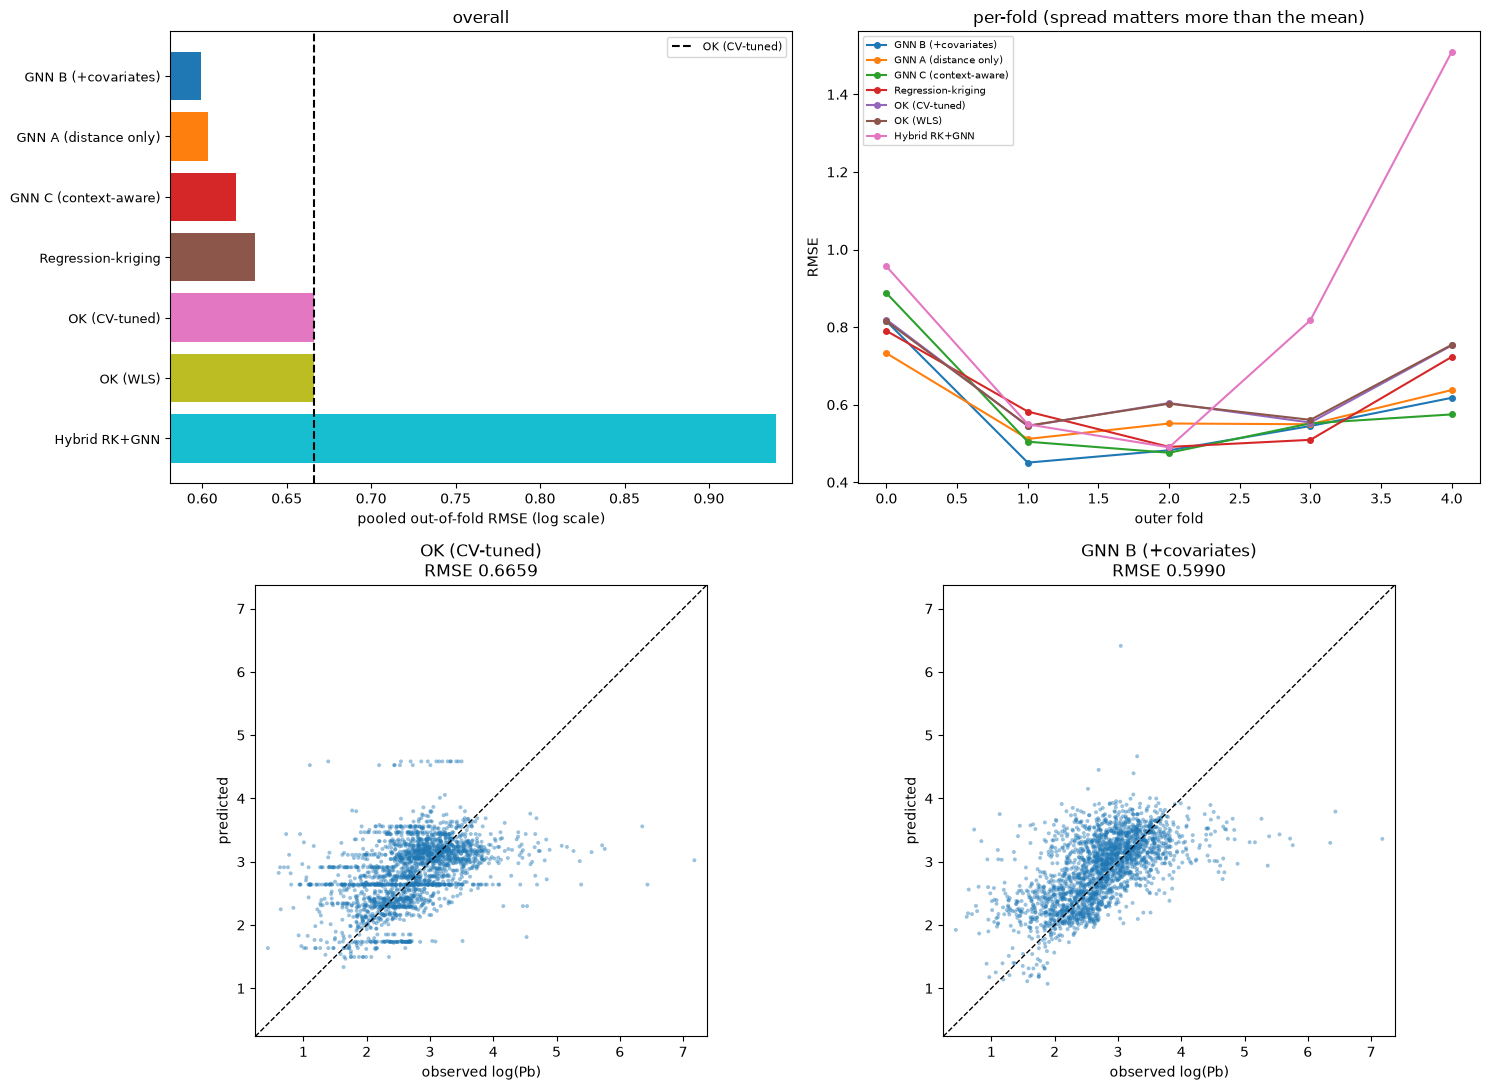

In [12]:
fig, ax = plt.subplots(2, 2, figsize=(15, 11))

order = TABLE.method.tolist()
colors = plt.cm.tab10(np.linspace(0, 1, len(order)))
ax[0, 0].barh(range(len(order)), TABLE.RMSE, color=colors)
ax[0, 0].set_yticks(range(len(order))); ax[0, 0].set_yticklabels(order, fontsize=9)
ax[0, 0].axvline(scores(Z, POOLED[BASE])["RMSE"], color="k", ls="--",
                 label=f"{BASE}")
ax[0, 0].invert_yaxis(); ax[0, 0].set_xlabel("pooled out-of-fold RMSE (log scale)")
ax[0, 0].set_title("overall"); ax[0, 0].legend(fontsize=8)
ax[0, 0].set_xlim(TABLE.RMSE.min() * 0.97, TABLE.RMSE.max() * 1.01)

for m in order:
    ax[0, 1].plot(PF.fold, PF[m], "-o", ms=4, label=m)
ax[0, 1].set_xlabel("outer fold"); ax[0, 1].set_ylabel("RMSE")
ax[0, 1].set_title("per-fold (spread matters more than the mean)")
ax[0, 1].legend(fontsize=7)

best_gnn = min([m for m in METHODS if m.startswith("GNN") or m.startswith("Hybrid")],
               key=lambda m: scores(Z, POOLED[m])["RMSE"])
lim = [Z.min() - .2, Z.max() + .2]
for a, m in ((ax[1, 0], BASE), (ax[1, 1], best_gnn)):
    a.scatter(Z, POOLED[m], s=8, alpha=.45, edgecolor="none")
    a.plot(lim, lim, "k--", lw=1)
    a.set_xlim(lim); a.set_ylim(lim); a.set_aspect("equal")
    a.set_xlabel(f"observed log({TARGET})"); a.set_ylabel("predicted")
    a.set_title(f"{m}\nRMSE {scores(Z, POOLED[m])['RMSE']:.4f}")
plt.tight_layout(); plt.show()

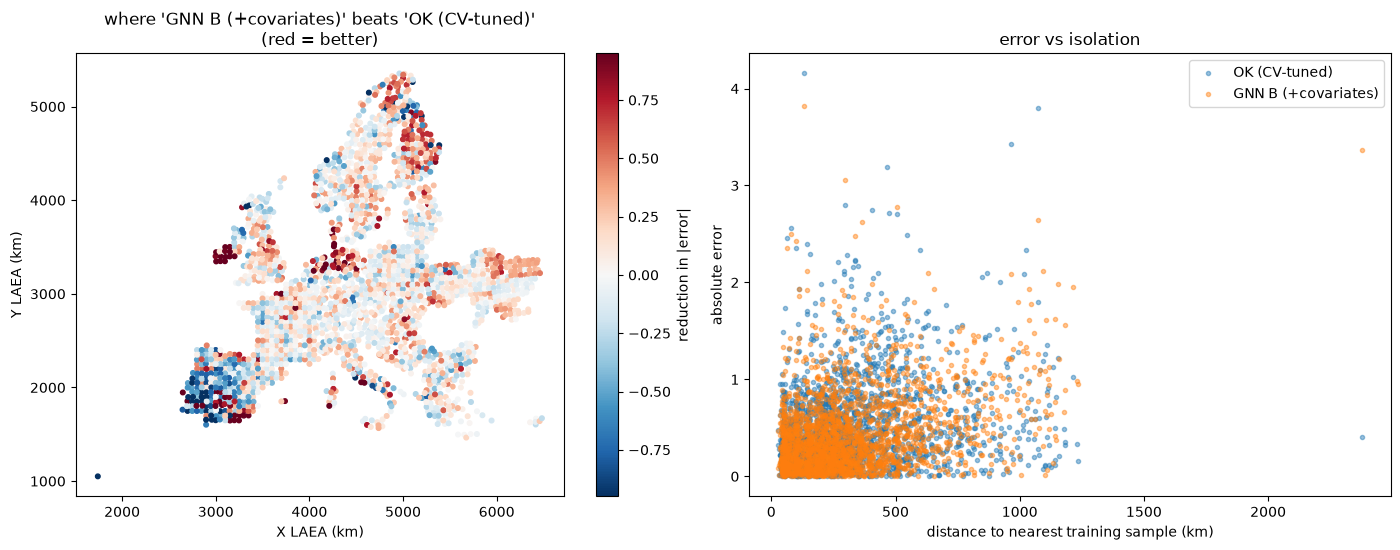

median distance to nearest training sample under spatial CV: 254 km
(a random split would give ~41 km -- the spatial folds are 6.2x harder)


In [13]:
# where does each method win or lose in space?
best_overall = TABLE.method.iloc[0]
diff = np.abs(POOLED[BASE] - Z) - np.abs(POOLED[best_overall] - Z)
XY_V = np.concatenate([XY[te] for _, te in OUTER])
fig, ax = plt.subplots(1, 2, figsize=(15, 5.6))
v = np.percentile(np.abs(diff), 97)
s = ax[0].scatter(XY_V[:, 0], XY_V[:, 1], c=diff, cmap="RdBu_r", vmin=-v, vmax=v, s=11)
ax[0].set_title(f"where '{best_overall}' beats '{BASE}'\n(red = better)")
plt.colorbar(s, ax=ax[0], fraction=.046, label="reduction in |error|")
dmin = np.concatenate([cdist(XY[te], XY[tr]).min(1) for tr, te in OUTER])
ax[1].scatter(dmin, np.abs(POOLED[BASE] - Z), s=9, alpha=.45, label=BASE)
ax[1].scatter(dmin, np.abs(POOLED[best_overall] - Z), s=9, alpha=.45, label=best_overall)
ax[1].set_xlabel("distance to nearest training sample (km)")
ax[1].set_ylabel("absolute error"); ax[1].legend(); ax[1].set_title("error vs isolation")
for a in (ax[0],):
    a.set_aspect("equal"); a.set_xlabel("X LAEA (km)"); a.set_ylabel("Y LAEA (km)")
plt.tight_layout(); plt.show()
print(f"median distance to nearest training sample under spatial CV: {np.median(dmin):.0f} km")
print(f"(a random split would give ~41 km -- the spatial folds are {np.median(dmin)/41:.1f}x harder)")

## 8. Decision

Same rule as before: a gain counts only if it beats the **honest** baseline
(`OK (CV-tuned)`) and does so consistently across spatial folds, not as a small mean
difference swamped by fold-to-fold spread.

In [14]:
b_rmse = scores(Z, POOLED[BASE])["RMSE"]
print("=" * 78)
print("DECISION")
print("=" * 78)
print(f"honest baseline '{BASE}': RMSE {b_rmse:.4f}")
print(f"{'OK (WLS), the usual baseline':<30}: {scores(Z, POOLED['OK (WLS)'])['RMSE']:.4f} "
      f"({100*(scores(Z,POOLED['OK (WLS)'])['RMSE']/b_rmse-1):+.1f}% vs honest)")
print("-" * 78)
learned = [m for m in METHODS if m.startswith("GNN") or m.startswith("Hybrid")]
verdict_any = False
for m in learned:
    s = scores(Z, POOLED[m])["RMSE"]
    d = (PF[m] - PF[BASE]).values
    rel = 100 * (s / b_rmse - 1)
    ok = (rel < 0) and ((d < 0).sum() >= 4) and (abs(d.mean()) > 0.5 * d.std())
    verdict_any |= ok
    print(f"{m:<26} {s:.4f}  {rel:+6.2f}%  folds better {(d<0).sum()}/{len(d)}  "
          f"mean {d.mean():+.4f} vs spread {d.std():.4f}  -> "
          f"{'KEEP' if ok else 'reject'}")
print("-" * 78)
print(f"model A (distance only) is the control: it CANNOT be non-stationary.")
dA = scores(Z, POOLED['GNN A (distance only)'])["RMSE"]
for m in ("GNN B (+covariates)", "GNN C (context-aware)"):
    print(f"  {m:<26} vs A: {100*(scores(Z,POOLED[m])['RMSE']/dA-1):+6.2f}%   "
          f"<- gain attributable to local conditioning")
print()
print("VERDICT:", "at least one learned model earns its place."
      if verdict_any else
      "no learned model clears the honest baseline consistently; retain kriging.")

DECISION
honest baseline 'OK (CV-tuned)': RMSE 0.6659
OK (WLS), the usual baseline  : 0.6663 (+0.1% vs honest)
------------------------------------------------------------------------------
GNN A (distance only)      0.6033   -9.39%  folds better 5/5  mean -0.0584 vs spread 0.0390  -> KEEP
GNN B (+covariates)        0.5990  -10.04%  folds better 5/5  mean -0.0728 vs spread 0.0557  -> KEEP
GNN C (context-aware)      0.6198   -6.92%  folds better 4/5  mean -0.0560 vs spread 0.0879  -> KEEP
Hybrid RK+GNN              0.9398  +41.14%  folds better 1/5  mean +0.2097 vs spread 0.3015  -> reject
------------------------------------------------------------------------------
model A (distance only) is the control: it CANNOT be non-stationary.
  GNN B (+covariates)        vs A:  -0.72%   <- gain attributable to local conditioning
  GNN C (context-aware)      vs A:  +2.72%   <- gain attributable to local conditioning

VERDICT: at least one learned model earns its place.
